# Задача 5. Обучение без учителя

* **Дедлайн**: 14.03.2025, 23:59
* **Основной полный балл**: 5
* **Максимум баллов**: 10

## Задача

- [x] Найти данные с количеством признаков хотя бы 50, на которых можно решить задачу кластеризации.
- [x] Выполнить разведочный анализ (**EDA**). При необходимости выполнить полезные преобразования данных.
- [x] Самостоятельно реализовать один из алгоритмов кластеризации (**K-means**).
- [x] Обучить модели кластеризации, используя свою реализацию, а также реализации из **sklearn**: **KMeans**, **Affinity Propagation**, **DBSCAN**.
- [x] При обучении использовать **подбор гиперпараметров**.
- [x] Сравнить качество моделей: замерить скорость обучения, вычислить различные метрики качества.
- [x] * (**+3 балла**) Снизить размерность данных с помощью **PCA** и оценить качество кластеризации всеми реализациями при различном количестве главных компонент.
- [x] * (**+2 балла**) Визуализировать данные, снизив размерность до 2 с помощью **PCA** и **t-SNE**. Для ускорения **t-SNE** сначала снизим размерность с помощью **PCA**.

## Imports

In [1]:
import re
from datetime import datetime
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna

from sklearn.base import BaseEstimator, ClusterMixin
from sklearn.cluster import KMeans, AffinityPropagation, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, rand_score)
from sklearn.manifold import TSNE
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from scipy.spatial.distance import cdist

optuna.logging.set_verbosity(optuna.logging.WARNING)
%matplotlib inline

## Данные: House Prices (Ames, Iowa)

**Источник:** [Kaggle: House Prices - Advanced Regression Techniques](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques)

**Контекст.** Классический датасет соревнования по предсказанию цен на жильё в Эймсе (Айова) с подробной информацией о каждом доме:
площади, качество материалов, количество комнат, состояние, этажность, гараж, бассейн и т.д.

**Почему подходит для кластеризации.** Каждый дом описывается признаками своего «сегмента»: бюджетное жильё, дома среднего
класса, элитная недвижимость. Задача без учителя — найти эти сегменты (кластеры) только по характеристикам домов, без цен.
Цена `SalePrice` не используется при обучении, но по ней мы сможем проверить качество кластеризации: разобьём цены на 4
квантильных сегмента и сравним их с найденными кластерами.

**Размеры:** 1460 объектов, 81 колонка (80 признаков + цена), из них более 50 численных/кодируемых признаков.

## Разведочный анализ (EDA)

In [2]:
df = pd.read_csv("../data/house_price/train.csv")
print(f"Объектов: {len(df)}, признаков: {df.shape[1]}")
df.head()

Объектов: 1460, признаков: 81


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [4]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(f"Колонок с пропусками: {len(missing)}")
missing

Колонок с пропусками: 19


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

Посмотрим на пропущенные значения. В этом датасете `NaN` в категориальных колонках (`Alley`, `PoolQC`, `Fence`, ...) часто означают
«объекта нет» — например, у дома нет бассейна или аллеи. Численные пропуски (`LotFrontage`, `MasVnrArea`, `GarageYrBlt`) заполним
медианой, категориальные — строкой `None`.

In [5]:
num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(exclude=np.number).columns

# Численные пропуски -> медиана (устойчива к выбросам)
df[num_cols] = df[num_cols].fillna(df[num_cols].median(numeric_only=True))
# Категориальные пропуски -> "None" (обычно означает отсутствие объекта: нет бассейна, гаража и т.п.)
df[cat_cols] = df[cat_cols].fillna("None")

print("Осталось пропусков:", df.isna().sum().sum())
print("Строк после обработки пропусков:", len(df))

Осталось пропусков: 0
Строк после обработки пропусков: 1460


Посмотрим на распределения численных признаков.

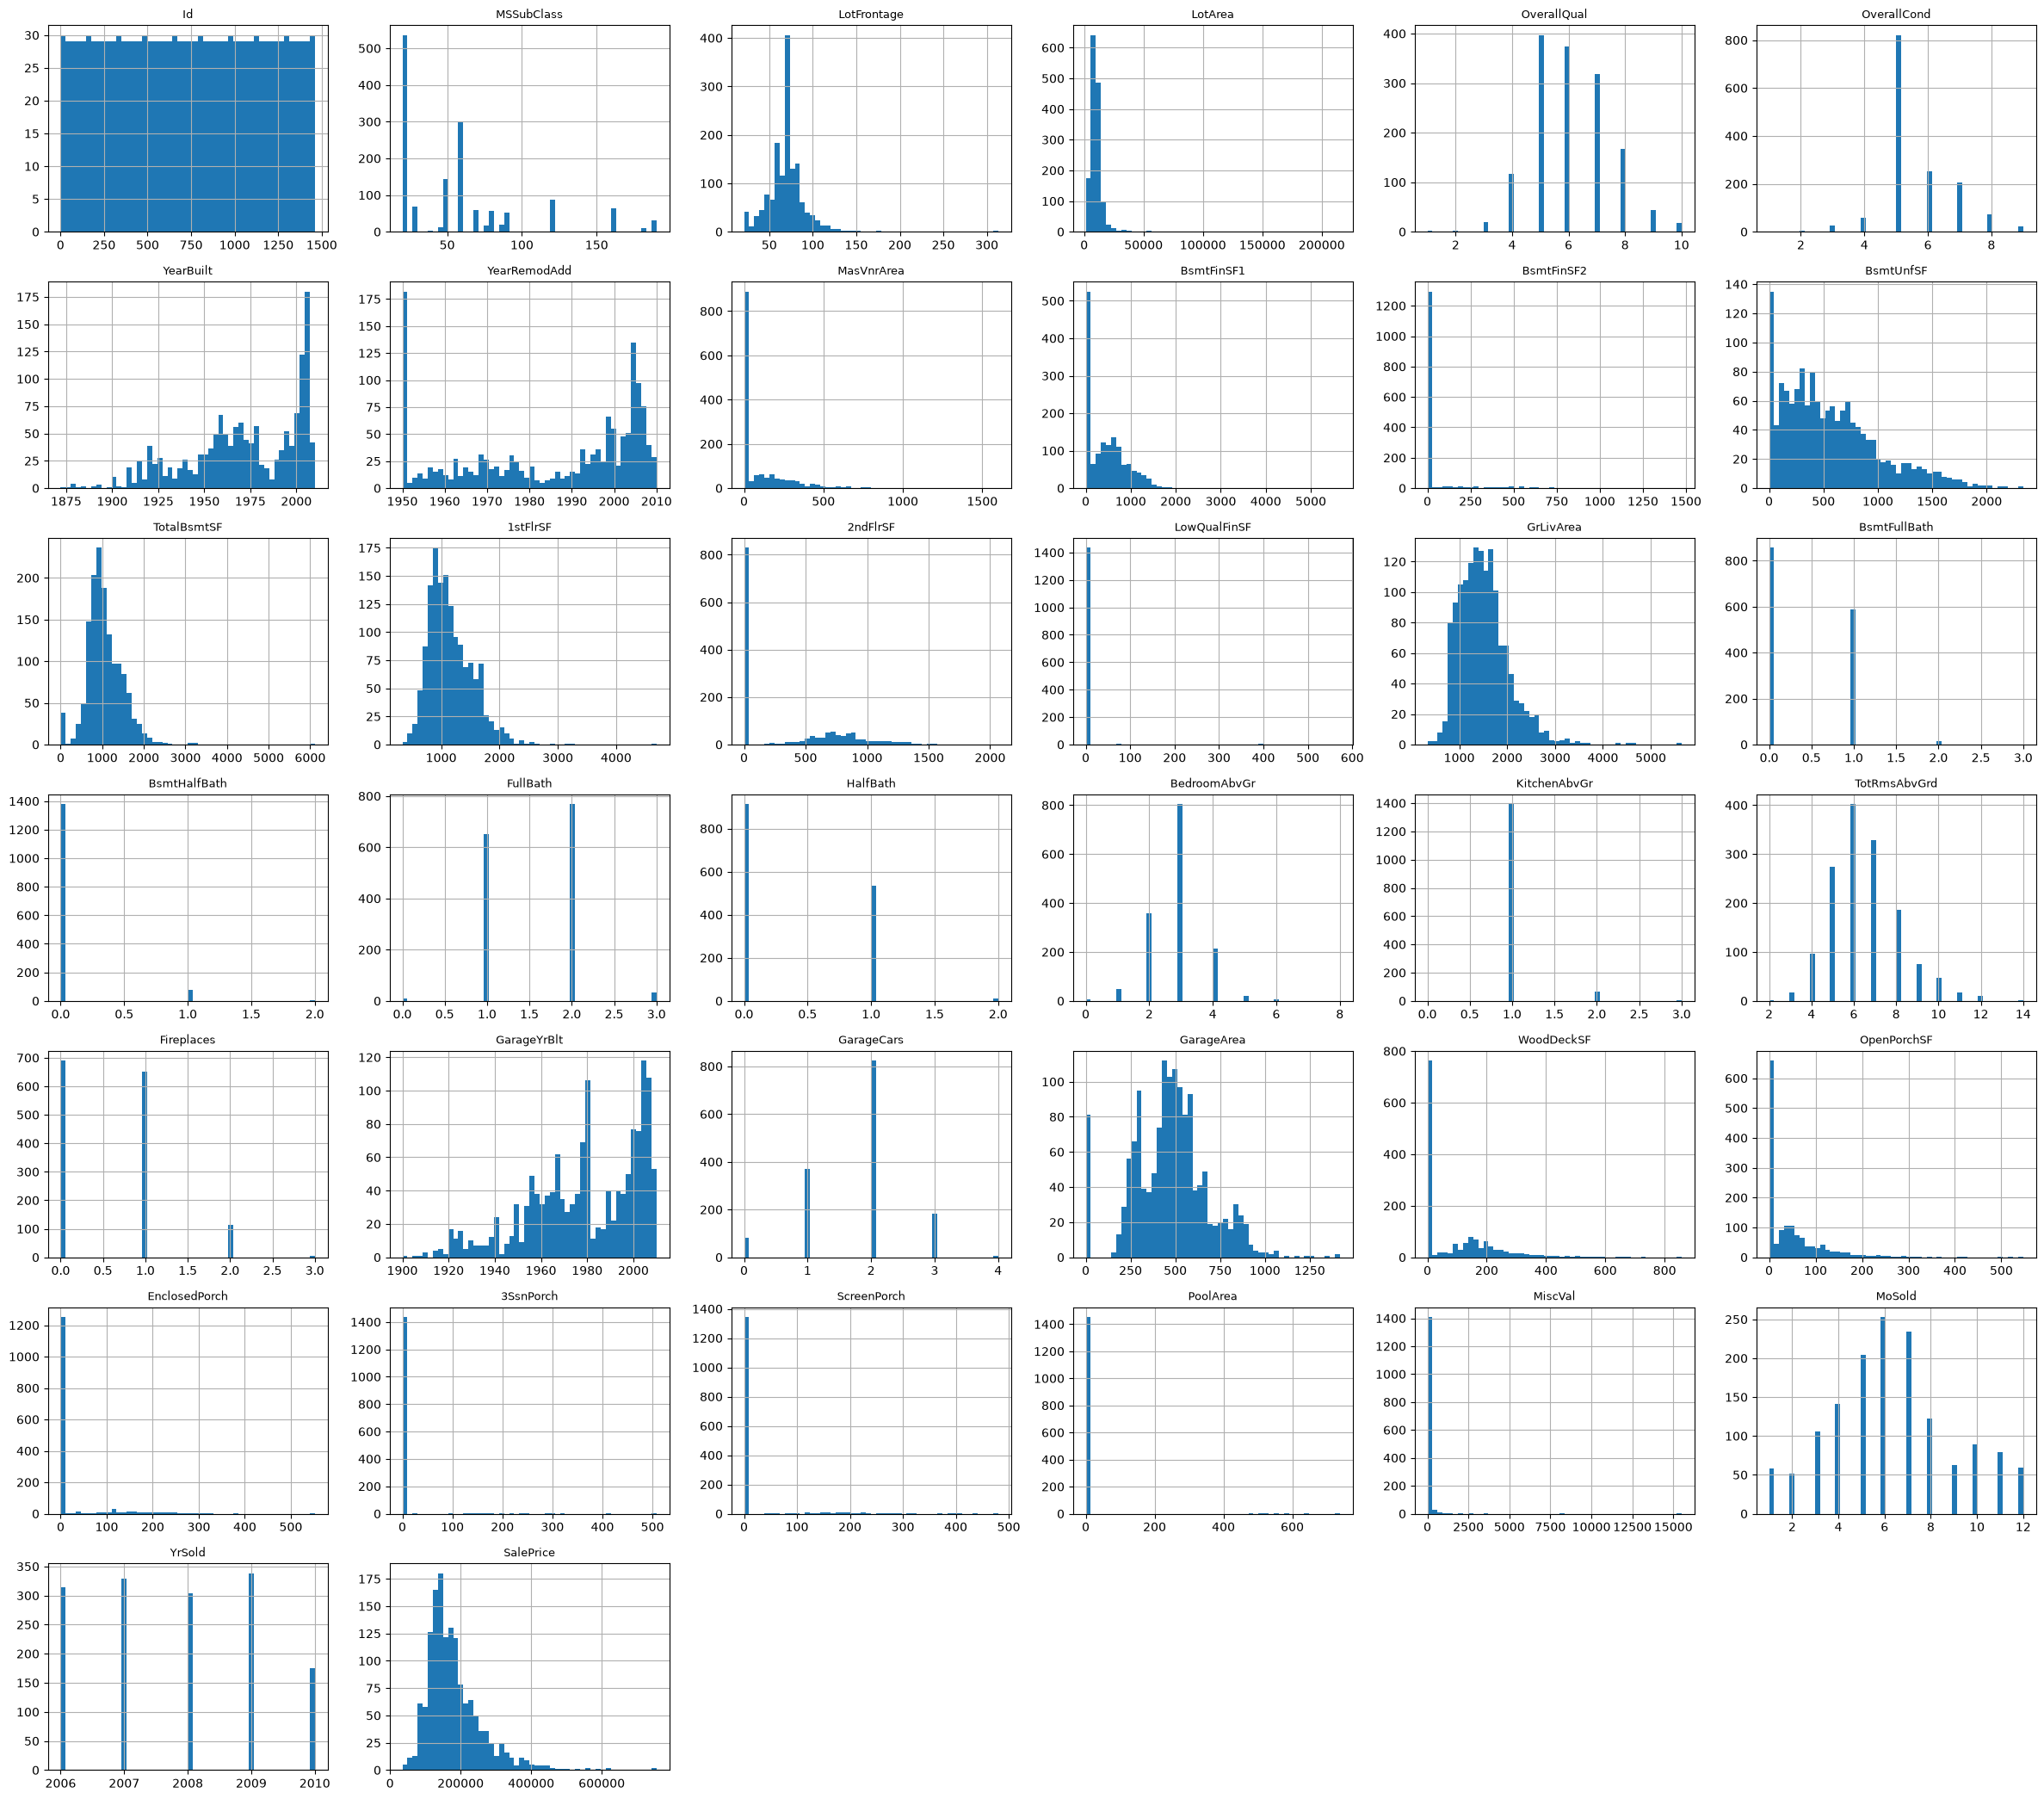

In [6]:
num_cols = df.select_dtypes(include=np.number).columns
n = len(num_cols)
fig, axes = plt.subplots(nrows=(n // 6) + 1, ncols=6, figsize=(24, (n // 6 + 1) * 3))
for i, col in enumerate(num_cols):
    ax = axes[i // 6, i % 6]
    df[col].hist(bins=50, ax=ax)
    ax.set_title(col, fontsize=9)
for i in range(n, axes.size):
    axes[i // 6, i % 6].axis("off")
plt.tight_layout()
plt.show()

Закодируем категориальные признаки целыми числами (`LabelEncoder`) и посмотрим на корреляционную матрицу.

Категориальных признаков: 43


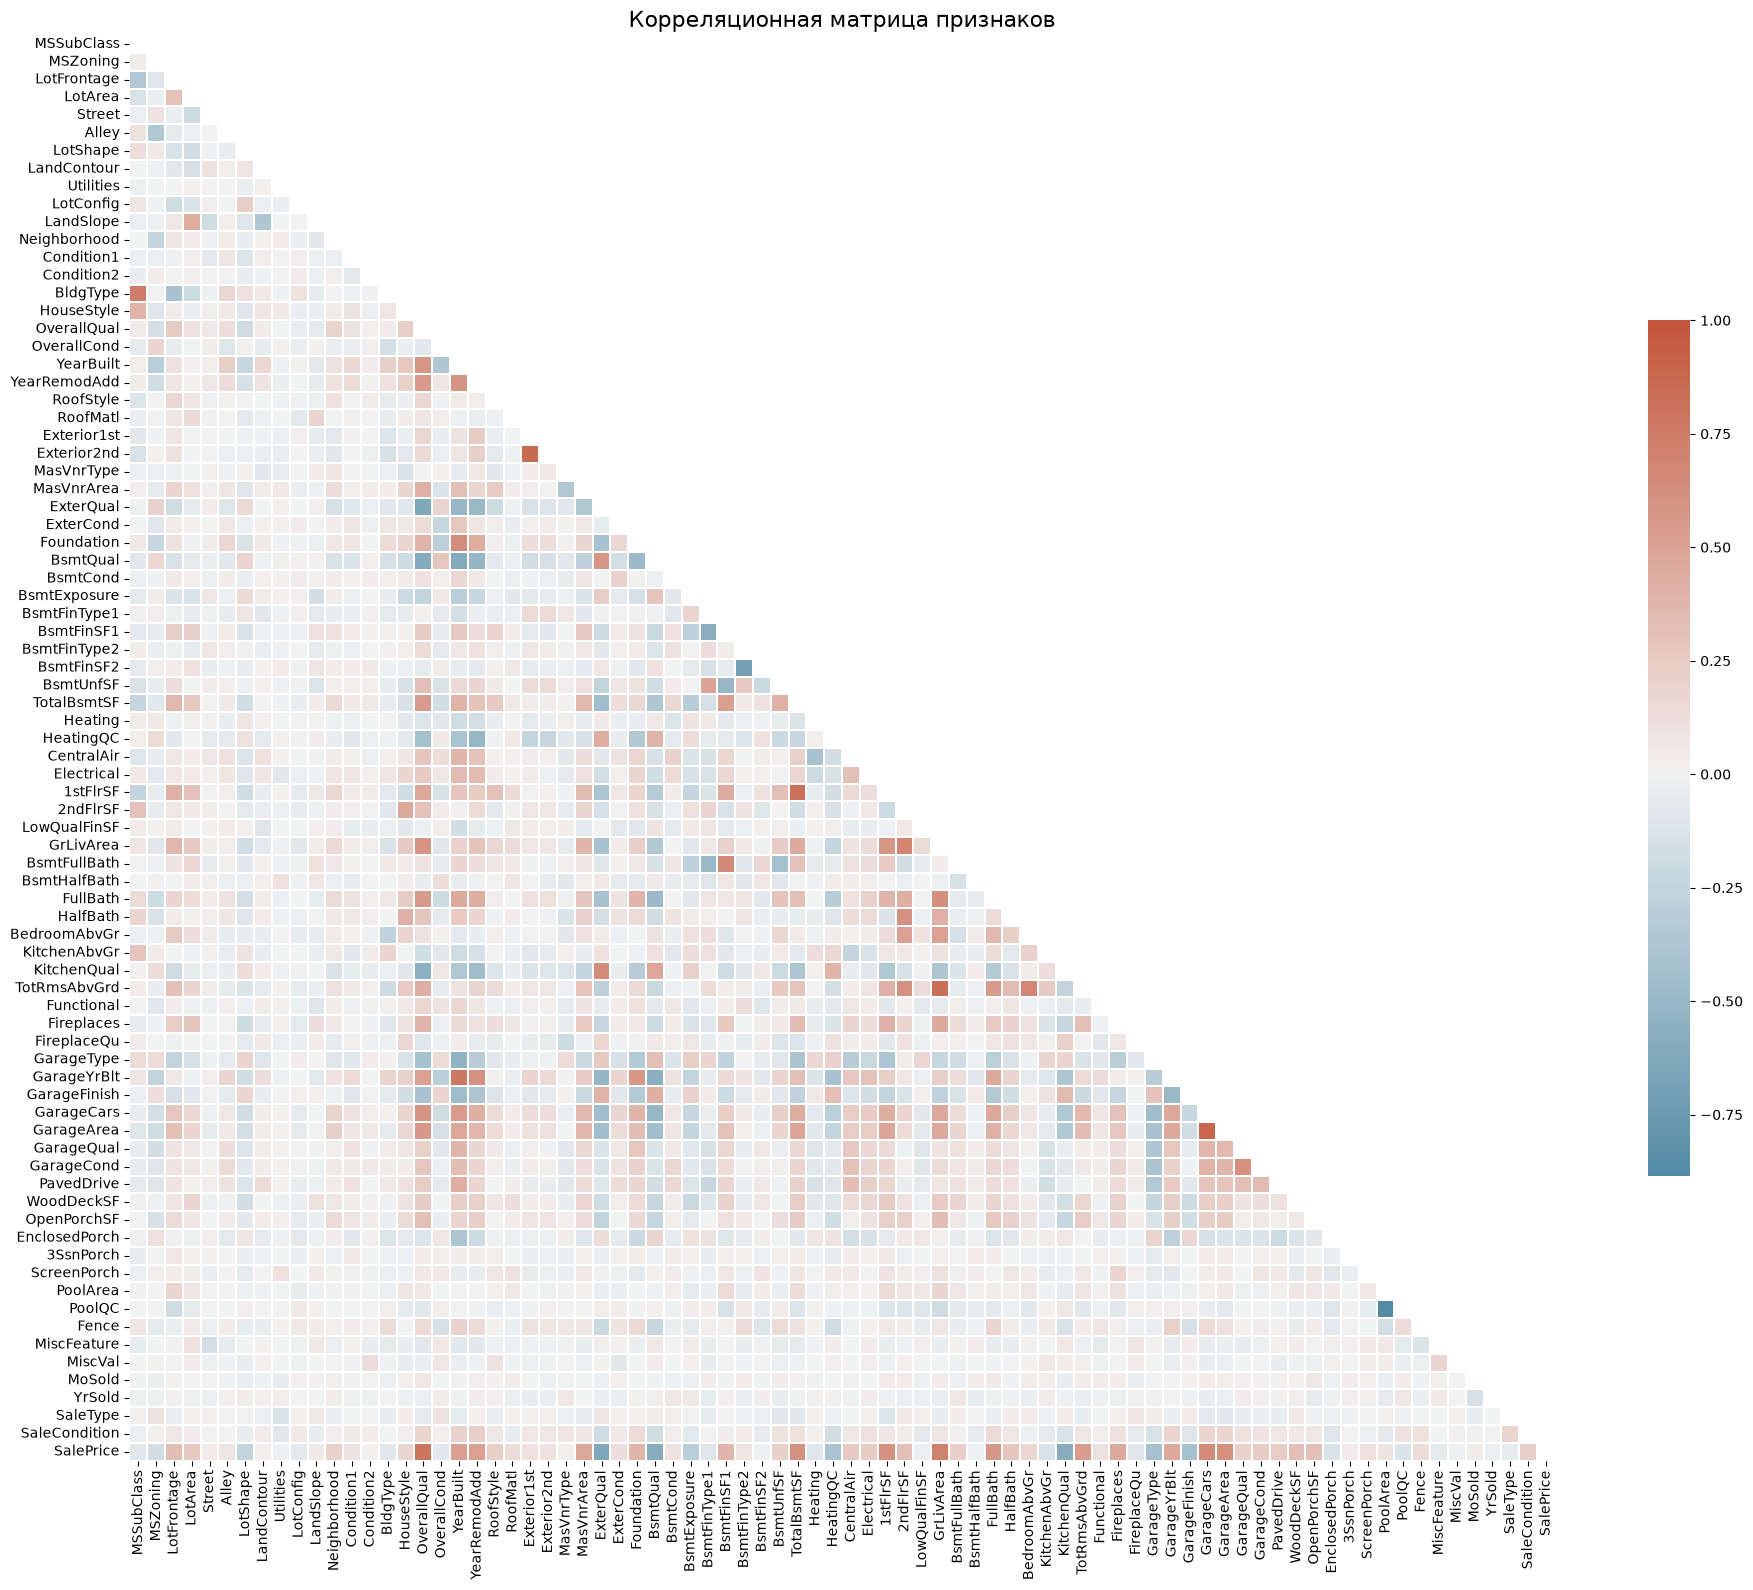

In [7]:
cat_cols = df.select_dtypes(exclude=np.number).columns
print(f"Категориальных признаков: {len(cat_cols)}")

encoder = LabelEncoder()
for col in cat_cols:
    df[col] = encoder.fit_transform(df[col])

df = df.drop(columns=["Id"])

f, ax = plt.subplots(figsize=(20, 16))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)
sns.heatmap(corr, mask=mask, cmap=cmap, vmax=1, center=0, square=True,
            linewidths=0.3, cbar_kws={"shrink": 0.6}, ax=ax)
plt.title("Корреляционная матрица признаков", fontsize=16)
plt.tight_layout()
plt.show()

По матрице корреляций видно, что сильных связей (|corr| > 0.9) после кодирования категориальных признаков нет — самые
заметные пары (`GarageYrBlt`/`YearBuilt`, площади этажей) коррелируют умеренно (0.7–0.9). Проверим это формально и удалим
такие пары, если найдутся (из пары удаляем признак, который чаще участвует в сильных связях) — это упростит интерпретацию
кластеров и компонент PCA.

In [8]:
# Удаляем из каждой пары |corr| > 0.9 тот признак, который чаще участвует в сильных связях
corr = df.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
strong = upper.stack()
strong = strong[strong > 0.9]

deleted = set()
for (c1, c2), _ in strong.items():
    if c1 in deleted or c2 in deleted:
        continue
    c1_links = (strong.index.get_level_values(0) == c1).sum() + (strong.index.get_level_values(1) == c1).sum()
    c2_links = (strong.index.get_level_values(0) == c2).sum() + (strong.index.get_level_values(1) == c2).sum()
    deleted.add(c1 if c1_links >= c2_links else c2)

df = df.drop(columns=list(deleted))
print(f"Удалено признаков: {len(deleted)} -> {list(deleted)}")
print(f"Осталось признаков (без цены): {df.shape[1] - 1}")

Удалено признаков: 0 -> []
Осталось признаков (без цены): 79


Проверим, что признаков осталось хотя бы 50.

`SalePrice` отложим как «истинные» метки для внешней проверки: разобьём цены на **4 сегмента** (дешёвые, средние, выше среднего,
дорогие дома) квартилями. На кластеризацию цена влиять не будет — признаки кластеризации ее не содержат.

Далее отмасштабируем признаки (`StandardScaler`) — все алгоритмы кластеризации чувствительны к масштабу, — и разобьём выборку на train/test (кластеризуем на train, метрики качества считаем на test).

In [9]:
X = df.drop(columns=["SalePrice"])
y_segments = pd.qcut(df["SalePrice"], q=4, labels=[0, 1, 2, 3]).astype(int).values

print("Признаков для кластеризации:", X.shape[1], "(требование: >= 50)")
print("Объектов:", X.shape[0])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_segments, test_size=0.3, random_state=1337
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Признаков для кластеризации: 79 (требование: >= 50)
Объектов: 1460
Train: (1022, 79), Test: (438, 79)


### Выбор числа кластеров: метод локтя (inertia)

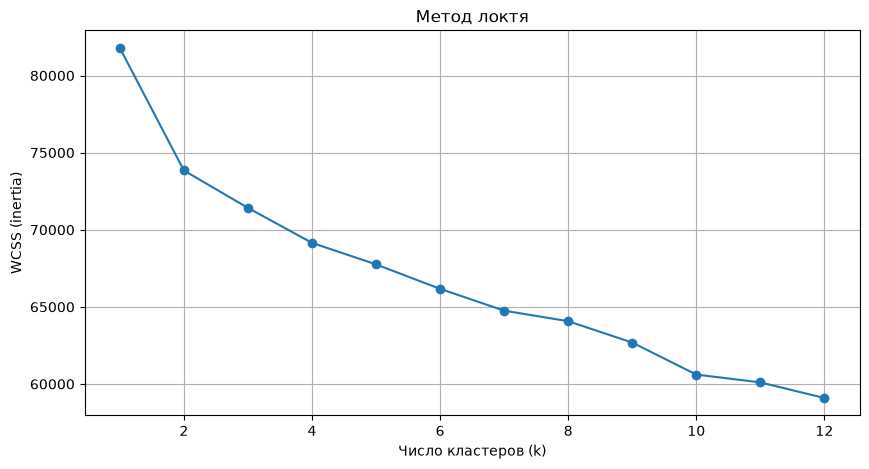

In [10]:
wcss = []
for k in range(1, 13):
    kmeans = KMeans(n_clusters=k, random_state=1337, n_init=10).fit(X_train)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(10, 5))
plt.plot(range(1, 13), wcss, marker="o")
plt.xlabel("Число кластеров (k)")
plt.ylabel("WCSS (inertia)")
plt.title("Метод локтя")
plt.grid(True)
plt.show()

### Выбор числа кластеров: индекс Дэвиса–Булдина и силуэт
(чем меньше Дэвис–Булдин, тем лучше; чем больше силуэт, тем лучше)

k= 2: Davies-Bouldin=2.821, Silhouette=0.1014
k= 3: Davies-Bouldin=3.499, Silhouette=0.0741
k= 4: Davies-Bouldin=3.401, Silhouette=0.0432
k= 5: Davies-Bouldin=3.241, Silhouette=0.0355
k= 6: Davies-Bouldin=3.352, Silhouette=0.0494
k= 7: Davies-Bouldin=3.071, Silhouette=0.0520
k= 8: Davies-Bouldin=2.342, Silhouette=0.0694
k= 9: Davies-Bouldin=2.527, Silhouette=0.0263
k=10: Davies-Bouldin=2.206, Silhouette=0.0685
k=11: Davies-Bouldin=2.364, Silhouette=0.0398
k=12: Davies-Bouldin=2.685, Silhouette=0.0431


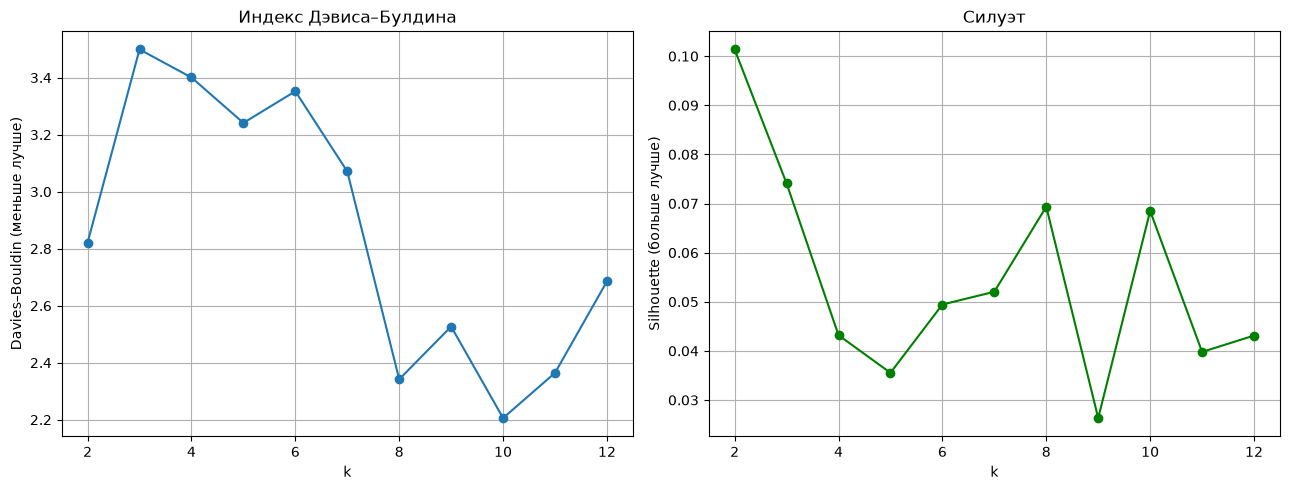

In [11]:
davies, sil = [], []
for k in range(2, 13):
    labels = KMeans(n_clusters=k, random_state=1337, n_init=10).fit_predict(X_train)
    davies.append(davies_bouldin_score(X_train, labels))
    sil.append(silhouette_score(X_train, labels))

for k, d, s in zip(range(2, 13), davies, sil):
    print(f"k={k:2d}: Davies-Bouldin={d:.3f}, Silhouette={s:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(range(2, 13), davies, marker="o")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Davies–Bouldin (меньше лучше)")
axes[0].set_title("Индекс Дэвиса–Булдина"); axes[0].grid(True)
axes[1].plot(range(2, 13), sil, marker="o", color="green")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette (больше лучше)")
axes[1].set_title("Силуэт"); axes[1].grid(True)
plt.tight_layout()
plt.show()

Метод локтя показывает резкое замедление падения инерции после k = 3–4. Индекс Дэвиса–Булдина и силуэт не дают
однозначного экстремума: значения шумные, а силуэт всюду меньше 0.11 — кластерная структура в данных слабая (дома образуют
«размытые» группы, а не изолированные сгустки). Возьмём **k = 4**: силуэт при k = 4 (0.043) сопоставим с соседними
значениями k = 3–7 (0.036–0.074), а главное — это согласуется с гипотезой о четырёх ценовых сегментах жилья (бюджетное,
среднее, выше среднего, дорогое), которые мы используем для внешней проверки кластеров.

## Своя реализация K-means (`MyKMeans`)

Реализуем K-means «с нуля» в стиле sklearn (`BaseEstimator`, `ClusterMixin`), поддерживая два способа инициализации центроидов:
случайный и **k-means++** (вероятностный выбор далёких друг от друга центров). Как и в sklearn, поддерживаем несколько
рестартов `n_init` — из всех запусков оставляем тот, что дал минимальную инерцию (WCSS). Классический алгоритм:

1. Инициализация центроидов (случайно или k-means++);
2. Присвоение каждому объекту ближайшего центроида;
3. Пересчёт центроидов как средних по кластерам;
4. Повтор 2–3, пока центроиды не сойдутся (сдвиг < `tol`) или не закончатся итерации.

In [12]:
class MyKMeans(BaseEstimator, ClusterMixin):
    """K-means, реализованный вручную (в стиле sklearn)."""

    def __init__(self, n_clusters=4, max_iter=100, tol=1e-4, init="k-means++", n_init=10):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.init = init
        self.n_init = n_init

    def _init_centroids(self, X, rng):
        n_samples = len(X)
        if self.init == "random":
            idx = rng.choice(n_samples, self.n_clusters, replace=False)
            return X[idx].copy()
        # k-means++: первый центр случайный, далее — с вероятностью, пропорциональной квадрату расстояния
        centroids = [X[rng.integers(n_samples)]]
        for _ in range(1, self.n_clusters):
            d2 = np.min(np.sum((X[:, None, :] - np.asarray(centroids)[None, :, :]) ** 2, axis=2), axis=1)
            probs = d2 / d2.sum()
            centroids.append(X[rng.choice(n_samples, p=probs)])
        return np.asarray(centroids)

    def _fit_once(self, X, seed):
        rng = np.random.default_rng(seed)
        centroids = self._init_centroids(X, rng)
        for _ in range(self.max_iter):
            labels = self._assign(X, centroids)
            new_centroids = np.array([
                X[labels == j].mean(axis=0) if np.any(labels == j) else centroids[j]
                for j in range(self.n_clusters)
            ])
            shift = np.linalg.norm(centroids - new_centroids)
            centroids = new_centroids
            if shift < self.tol:
                break
        labels = self._assign(X, centroids)
        inertia = sum(np.sum((X[labels == j] - centroids[j]) ** 2) for j in range(self.n_clusters))
        return centroids, labels, inertia

    def _assign(self, X, centroids):
        d2 = np.sum((X[:, None, :] - centroids[None, :, :]) ** 2, axis=2)
        return np.argmin(d2, axis=1)

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        best = None
        for seed in range(1337, 1337 + self.n_init):  # несколько рестартов
            centroids, labels, inertia = self._fit_once(X, seed)
            if best is None or inertia < best[0]:
                best = (inertia, centroids, labels)
        self.inertia_, self.centroids_, self.labels_ = best
        return self

    def predict(self, X):
        return self._assign(np.asarray(X, dtype=float), self.centroids_)

Проверим корректность реализации двумя способами:

1. **Совпадение с sklearn при одинаковых начальных центроидах**: обучим `sklearn.KMeans` c `init` = центроиды, найденные
   `MyKMeans`, — при идентичных правилах обновления обе модели должны дать одну и ту же разметку (ARI = 1);
2. **Качество решений**: сравним инерцию (WCSS) и согласованность разметок `MyKMeans` и `sklearn.KMeans` с одинаковым числом
   рестартов `n_init=10`.

In [13]:
my = MyKMeans(n_clusters=4, init="k-means++", max_iter=300, tol=1e-6, n_init=10).fit(X_train)
sk = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=1337).fit(X_train)

from sklearn.metrics import adjusted_rand_score as ari
print("Inertia (WCSS): MyKMeans =", round(my.inertia_, 1), "| KMeans =", round(sk.inertia_, 1))
print("ARI(MyKMeans, KMeans) на train:", round(ari(my.labels_, sk.labels_), 4))

# Точная проверка: sklearn, стартующий с центроидов MyKMeans, должен дать ту же разметку (правила обновления идентичны)
sk_from_my = KMeans(n_clusters=4, init=my.centroids_, n_init=1, max_iter=1000, tol=1e-9).fit(X_train)
print("ARI(MyKMeans, KMeans от центроидов MyKMeans):", round(ari(my.labels_, sk_from_my.labels_), 8))

Inertia (WCSS): MyKMeans = 69168.7 | KMeans = 69150.3
ARI(MyKMeans, KMeans) на train: 0.7382
ARI(MyKMeans, KMeans от центроидов MyKMeans): 1.0


## Подбор гиперпараметров (Optuna)

Для каждой модели подберём гиперпараметры максимизацией среднего **силуэта** на 5-фолдовой кросс-валидации (20 trials).
`silhouette_score` не требует истинных меток — это корректный критерий для обучения без учителя.

In [14]:
def silhouette_scorer(estimator, X, y=None):
    """Кастомный скорер: силуэт предсказанных кластеров (не требует истинных меток).
    Возвращает -1.0 для вырожденных разметок (меньше 2 кластеров)."""
    labels = estimator.predict(X)
    if len(np.unique(labels)) < 2:
        return -1.0
    return silhouette_score(X, labels)


def create_objective(model_class, fixed_params, param_suggestions, X, y, n_splits=5):
    def objective(trial):
        params = {**fixed_params, **{k: v(trial, k) for k, v in param_suggestions.items()}}
        model = model_class(**params)
        cv = KFold(n_splits=n_splits, shuffle=True, random_state=42)
        try:
            scores = cross_val_score(model, X, y, scoring=silhouette_scorer, cv=cv, n_jobs=-1)
            return float(np.mean(scores))
        except Exception:
            return -1.0
    return objective


def run_study(objective, n_trials=20):
    study = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=n_trials)
    return study.best_params, study.best_value


def summarize(name, best_params, best_value, elapsed):
    print(f"{name}: best_value(silhouette) = {best_value:.4f} за {elapsed:.1f} с")
    print(f"  best_params = {best_params}")

### MyKMeans

In [15]:
t0 = perf_counter()
obj = create_objective(MyKMeans, {"n_clusters": 4}, {
    "init": lambda t, k: t.suggest_categorical(k, ["random", "k-means++"]),
    "n_init": lambda t, k: t.suggest_int(k, 1, 10),
    "max_iter": lambda t, k: t.suggest_categorical(k, [100, 200, 300, 500]),
    "tol": lambda t, k: t.suggest_float(k, 1e-5, 1e-2, log=True),
}, X_train, y_train)
best_MyKMeans, best_MyKMeans_value = run_study(obj)
summarize("MyKMeans", best_MyKMeans, best_MyKMeans_value, perf_counter() - t0)

MyKMeans: best_value(silhouette) = 0.0736 за 5.0 с
  best_params = {'init': 'k-means++', 'n_init': 1, 'max_iter': 100, 'tol': 3.5498788321965036e-05}


### KMeans (sklearn)

In [16]:
t0 = perf_counter()
obj = create_objective(KMeans, {"n_clusters": 4, "random_state": 1337}, {
    "init": lambda t, k: t.suggest_categorical(k, ["k-means++", "random"]),
    "n_init": lambda t, k: t.suggest_int(k, 1, 20),
    "max_iter": lambda t, k: t.suggest_categorical(k, [100, 200, 300, 500]),
    "tol": lambda t, k: t.suggest_float(k, 1e-5, 1e-2, log=True),
}, X_train, y_train)
best_KMeans, best_KMeans_value = run_study(obj)
summarize("KMeans", best_KMeans, best_KMeans_value, perf_counter() - t0)

KMeans: best_value(silhouette) = 0.0623 за 1.1 с
  best_params = {'init': 'random', 'n_init': 1, 'max_iter': 100, 'tol': 3.5498788321965036e-05}


### Affinity Propagation (sklearn)

Метки Affinity Propagation малостабильны на новых объектах: в sklearn у него нет `predict`, а перенос меток через
`fit_predict` на тестовой выборке переобучает модель. Поэтому обернём его в класс, который присваивает тестовому объекту
метку ближайшего объекта из обучающей выборки.

In [17]:
class AffinityWrap(BaseEstimator, ClusterMixin):
    """Обёртка над AffinityPropagation: predict через ближайшего соседа из train."""

    def __init__(self, damping=0.5, preference=None, convergence_iter=15, max_iter=200):
        self.damping = damping
        self.preference = preference
        self.convergence_iter = convergence_iter
        self.max_iter = max_iter

    def fit(self, X, y=None):
        X = np.asarray(X)
        pref = self.preference
        if pref is None:
            pref = float(np.median(cdist(X, X)))
        self.model_ = AffinityPropagation(
            damping=self.damping, preference=pref,
            convergence_iter=self.convergence_iter, max_iter=self.max_iter,
            random_state=1337).fit(X)
        self.labels_ = self.model_.labels_
        self.X_train_ = X
        return self

    def predict(self, X):
        X = np.asarray(X)
        d = cdist(X, self.X_train_)
        return self.labels_[np.argmin(d, axis=1)]

In [18]:
t0 = perf_counter()
obj = create_objective(AffinityWrap, {}, {
    "damping": lambda t, k: t.suggest_float(k, 0.5, 0.9, step=0.05),
    "convergence_iter": lambda t, k: t.suggest_int(k, 5, 40),
    "max_iter": lambda t, k: t.suggest_categorical(k, [100, 200, 400]),
}, X_train, y_train)
best_Affinity, best_Affinity_value = run_study(obj)
summarize("AffinityPropagation", best_Affinity, best_Affinity_value, perf_counter() - t0)

AffinityPropagation: best_value(silhouette) = -0.0140 за 20.4 с
  best_params = {'damping': 0.65, 'convergence_iter': 39, 'max_iter': 100}


### DBSCAN (sklearn)

У DBSCAN тоже нет `predict`. Сделаем обёртку: после обучения тестовому объекту присваивается метка его ближайшего соседа из
обучающей выборки. Шумовые точки (-1) переназначаются на ближайший нешумовой кластер, иначе метрики качества (силуэт) не
вычислить.

In [19]:
class DBSCANWrap(BaseEstimator, ClusterMixin):
    """Обёртка над DBSCAN: predict через ближайшего соседа из train; шум переназначается
    на ближайший нешумовой кластер (иначе метрики на -1 не вычислить)."""

    def __init__(self, eps=0.5, min_samples=5):
        self.eps = eps
        self.min_samples = min_samples

    def fit(self, X, y=None):
        X = np.asarray(X)
        raw = DBSCAN(eps=self.eps, min_samples=self.min_samples).fit_predict(X)
        clean = raw != -1
        if clean.any():
            d = cdist(X, X[clean])
            self.labels_ = raw[clean][np.argmin(d, axis=1)]
        else:
            self.labels_ = np.zeros(len(X), dtype=int)
        self.X_train_ = X
        return self

    def predict(self, X):
        X = np.asarray(X)
        d = cdist(X, self.X_train_)
        return self.labels_[np.argmin(d, axis=1)]

In [20]:
t0 = perf_counter()
obj = create_objective(DBSCANWrap, {}, {
    "eps": lambda t, k: t.suggest_float(k, 0.5, 30.0, log=True),
    "min_samples": lambda t, k: t.suggest_int(k, 2, 30),
}, X_train, y_train)
best_DBSCAN, best_DBSCAN_value = run_study(obj)
summarize("DBSCAN", best_DBSCAN, best_DBSCAN_value, perf_counter() - t0)

DBSCAN: best_value(silhouette) = -0.0764 за 1.1 с
  best_params = {'eps': 4.81613761959229, 'min_samples': 2}


## PCA и качество кластеризации при разном числе компонент (+3 балла)

Посмотрим, сколько дисперсии объясняют главные компоненты, и прогоним все модели при разном числе компонент
PCA (0 — без снижения размерности). PCA обучаем на train и применяем к train/test.

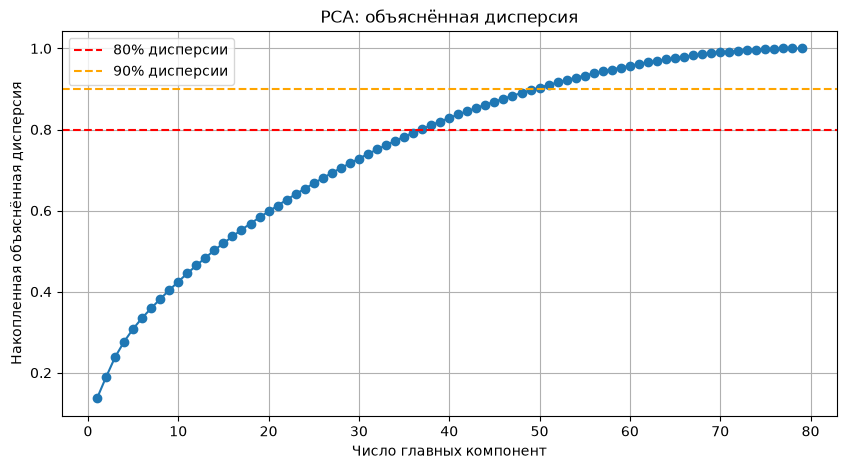

Для 80% дисперсии нужно 37 компонент
Для 90% дисперсии нужно 50 компонент
Для 95% дисперсии нужно 59 компонент


In [21]:
pca_full = PCA().fit(X_train)
cum = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(cum) + 1), cum, marker="o")
plt.axhline(0.8, color="red", linestyle="--", label="80% дисперсии")
plt.axhline(0.9, color="orange", linestyle="--", label="90% дисперсии")
plt.xlabel("Число главных компонент")
plt.ylabel("Накопленная объяснённая дисперсия")
plt.title("PCA: объяснённая дисперсия")
plt.legend(); plt.grid(True)
plt.show()

for thr in (0.8, 0.9, 0.95):
    k = int(np.argmax(cum >= thr) + 1)
    print(f"Для {thr:.0%} дисперсии нужно {k} компонент")

In [22]:
models = {
    "MyKMeans": MyKMeans(n_clusters=4, **best_MyKMeans),
    "KMeans": KMeans(n_clusters=4, random_state=1337, **best_KMeans),
    "AffinityPropagation": AffinityWrap(**best_Affinity),
    "DBSCAN": DBSCANWrap(**best_DBSCAN),
}
max_comp = X_train.shape[1]
pca_variants = sorted(set(c for c in [0, 5, 10, 15, 20, 30, 40, 50, max_comp] if c <= max_comp))

metrics = {name: {"rand": [], "train_time": [], "silhouette": [],
                  "calinski_harabasz": [], "davies_bouldin": []}
           for name in models}

for n_comp in pca_variants:
    if n_comp == 0:
        Xtr, Xte = X_train, X_test  # полная размерность
    else:
        pca = PCA(n_components=n_comp).fit(X_train)
        Xtr, Xte = pca.transform(X_train), pca.transform(X_test)

    for name, model in models.items():
        t0 = perf_counter()
        model.fit(Xtr)
        elapsed = perf_counter() - t0
        pred = model.predict(Xte)

        metrics[name]["rand"].append(rand_score(y_test, pred))
        metrics[name]["train_time"].append(elapsed)
        try:
            metrics[name]["silhouette"].append(silhouette_score(Xte, pred))
        except Exception:
            metrics[name]["silhouette"].append(np.nan)
        try:
            metrics[name]["calinski_harabasz"].append(calinski_harabasz_score(Xte, pred))
        except Exception:
            metrics[name]["calinski_harabasz"].append(np.nan)
        try:
            metrics[name]["davies_bouldin"].append(davies_bouldin_score(Xte, pred))
        except Exception:
            metrics[name]["davies_bouldin"].append(np.nan)

print("Готово")

Готово


Сравним модели: время обучения и метрики качества на тестовой выборке (Rand score против ценовых сегментов, силуэт,
Калински–Харабас, Дэвис–Булдин) при каждом числе компонент.

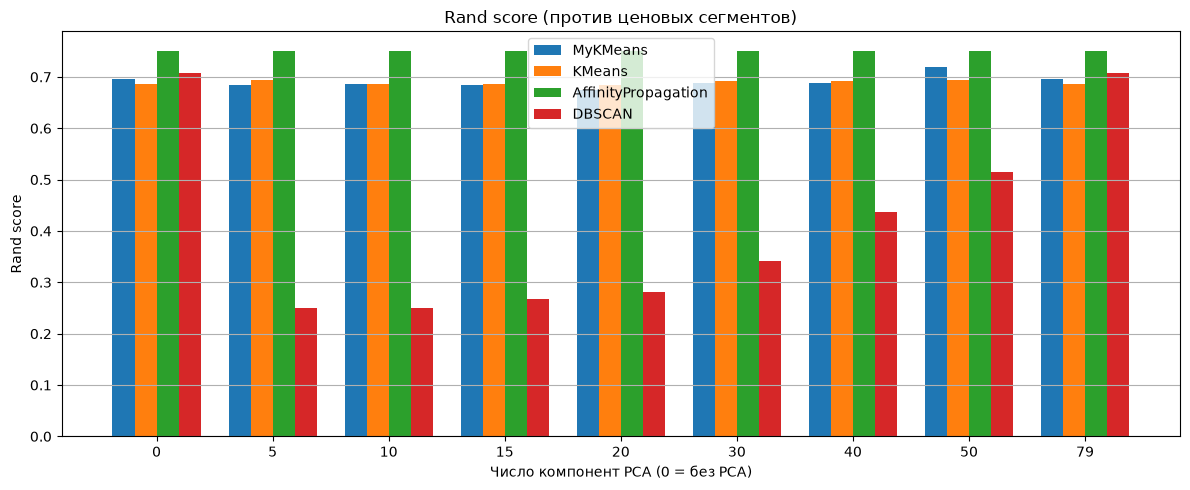

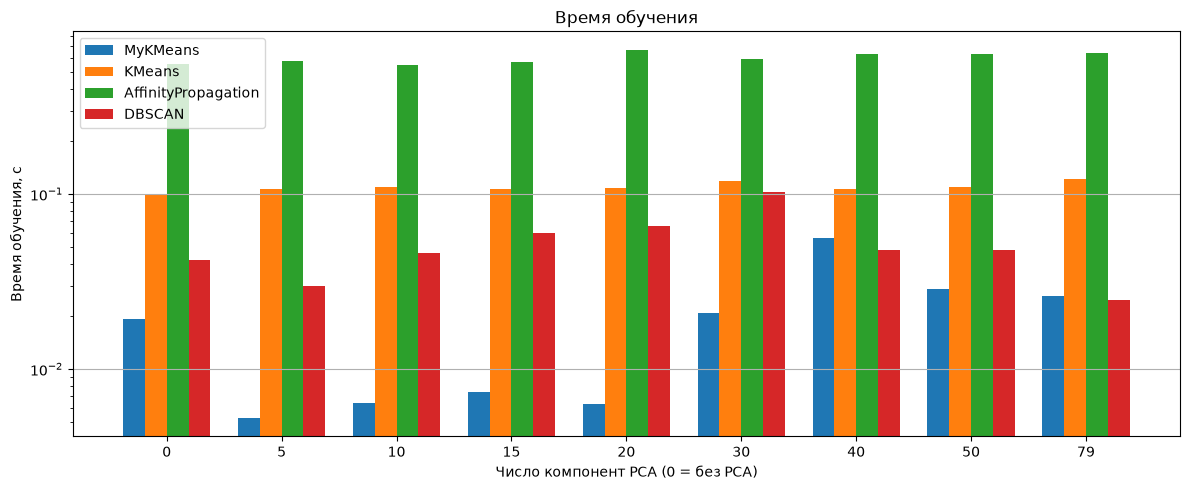

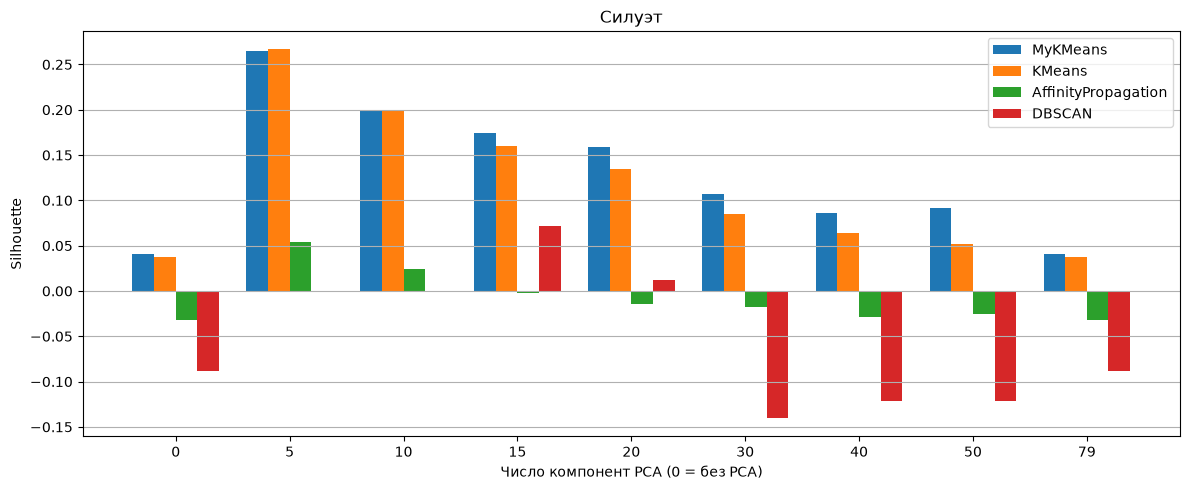

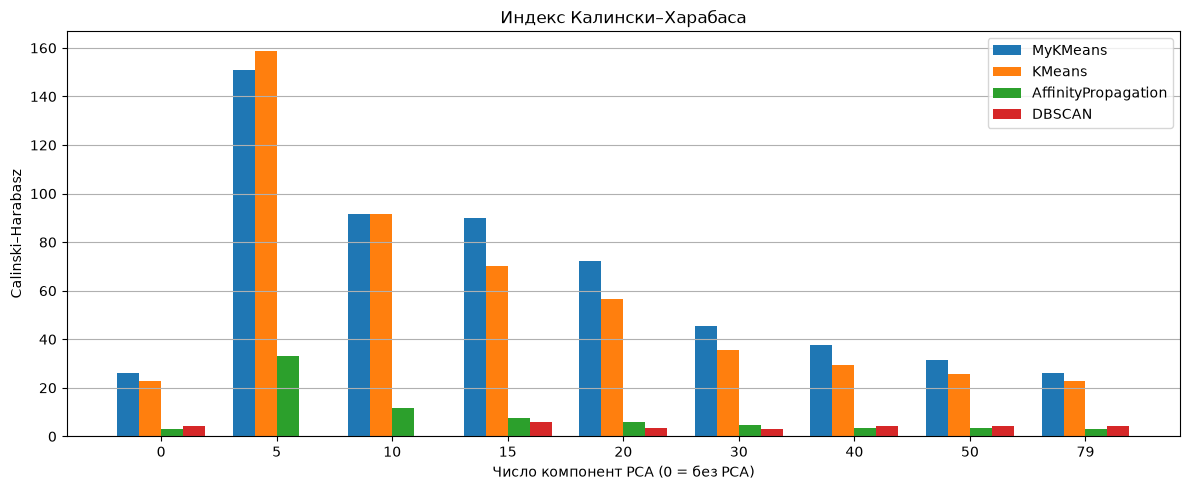

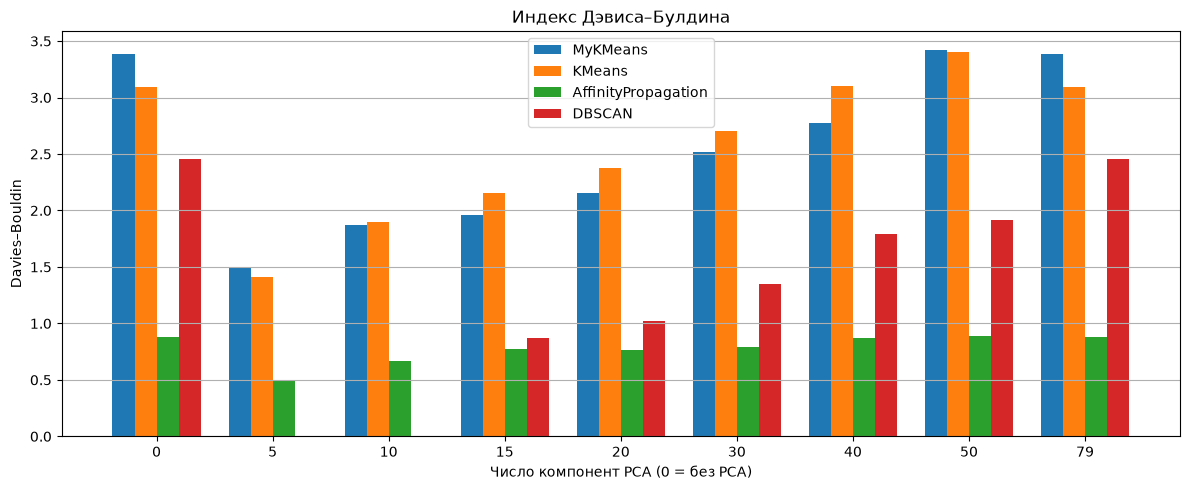

In [23]:
def plot_metric(metric_key, ylabel, title, log=False):
    plt.figure(figsize=(12, 5))
    bar_width = 0.19
    x = np.arange(len(pca_variants))
    for i, name in enumerate(models):
        vals = np.asarray(metrics[name][metric_key], dtype=float)
        plt.bar(x + i * bar_width, vals, width=bar_width, label=name)
    plt.xticks(x + 1.5 * bar_width, pca_variants)
    plt.xlabel("Число компонент PCA (0 = без PCA)")
    plt.ylabel(ylabel)
    plt.title(title)
    if log:
        plt.yscale("log")
    plt.legend(); plt.grid(axis="y")
    plt.tight_layout()
    plt.show()

plot_metric("rand", "Rand score", "Rand score (против ценовых сегментов)")
plot_metric("train_time", "Время обучения, с", "Время обучения", log=True)
plot_metric("silhouette", "Silhouette", "Силуэт")
plot_metric("calinski_harabasz", "Calinski–Harabasz", "Индекс Калински–Харабаса")
plot_metric("davies_bouldin", "Davies–Bouldin", "Индекс Дэвиса–Булдина")

In [24]:
rand_table = pd.DataFrame({
    "PCA": pca_variants,
    **{name: np.round(metrics[name]["rand"], 3) for name in models},
}).set_index("PCA")
print("Rand score (против ценовых сегментов) по числу компонент PCA:")
print(rand_table.to_string())

i20 = pca_variants.index(20)
print()
print("Время обучения при 20 компонентах PCA (с):")
print(pd.Series({name: round(metrics[name]["train_time"][i20], 4) for name in models}).to_string())

Rand score (против ценовых сегментов) по числу компонент PCA:
     MyKMeans  KMeans  AffinityPropagation  DBSCAN
PCA                                               
0       0.696   0.686                0.751   0.708
5       0.685   0.694                0.751   0.249
10      0.687   0.687                0.751   0.249
15      0.684   0.686                0.751   0.268
20      0.674   0.684                0.751   0.280
30      0.688   0.692                0.751   0.342
40      0.689   0.693                0.751   0.437
50      0.718   0.693                0.751   0.515
79      0.696   0.686                0.751   0.708

Время обучения при 20 компонентах PCA (с):
MyKMeans               0.0063
KMeans                 0.1083
AffinityPropagation    0.6667
DBSCAN                 0.0659


## Визуализация: PCA и t-SNE (+2 балла)

Снизим размерность до 2 с помощью PCA и t-SNE (t-SNE запустим на PCA-проекции до 50 компонент — это ускоряет t-SNE и
убирает шум). Окрасим точки по ценовым сегментам и по кластерам `MyKMeans`.

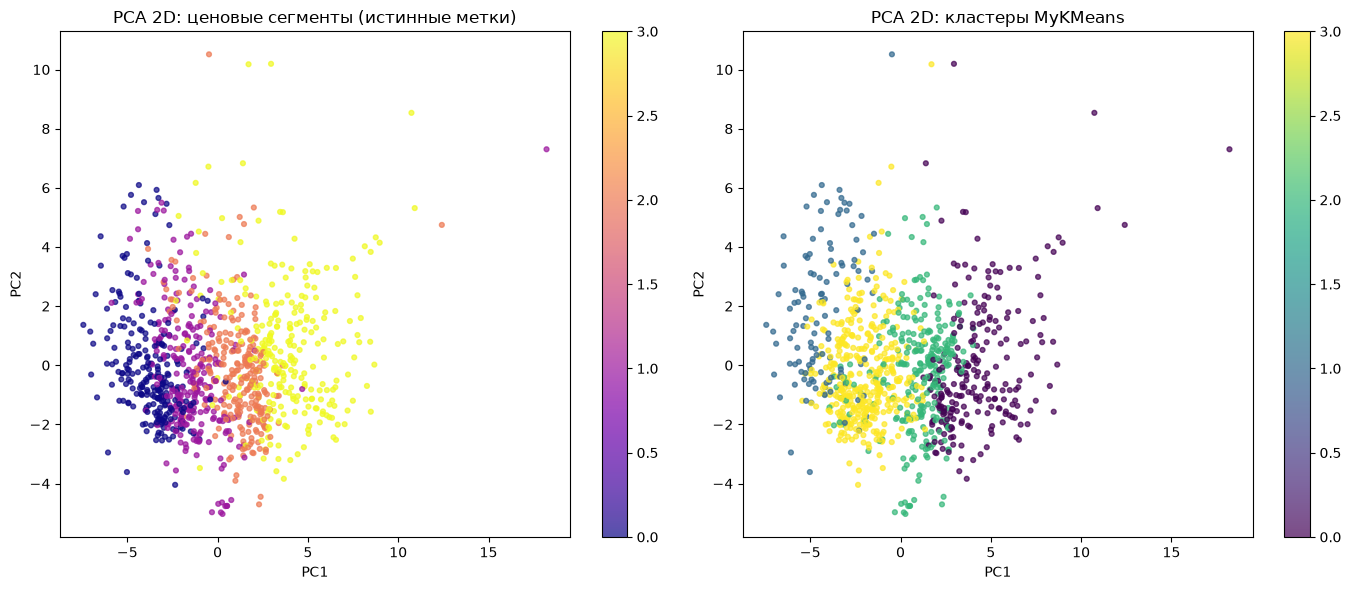

In [25]:
pca2 = PCA(n_components=2, random_state=42).fit_transform(X_train)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sc1 = axes[0].scatter(pca2[:, 0], pca2[:, 1], c=y_train, cmap="plasma", s=12, alpha=0.7)
axes[0].set_title("PCA 2D: ценовые сегменты (истинные метки)")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
plt.colorbar(sc1, ax=axes[0])

my_final = MyKMeans(n_clusters=4, **best_MyKMeans).fit(X_train)
sc2 = axes[1].scatter(pca2[:, 0], pca2[:, 1], c=my_final.labels_, cmap="viridis", s=12, alpha=0.7)
axes[1].set_title("PCA 2D: кластеры MyKMeans")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
plt.colorbar(sc2, ax=axes[1])
plt.tight_layout()
plt.show()

PCA 50 компонент объясняют 90.4% дисперсии


t-SNE выполнен за 1.9 с


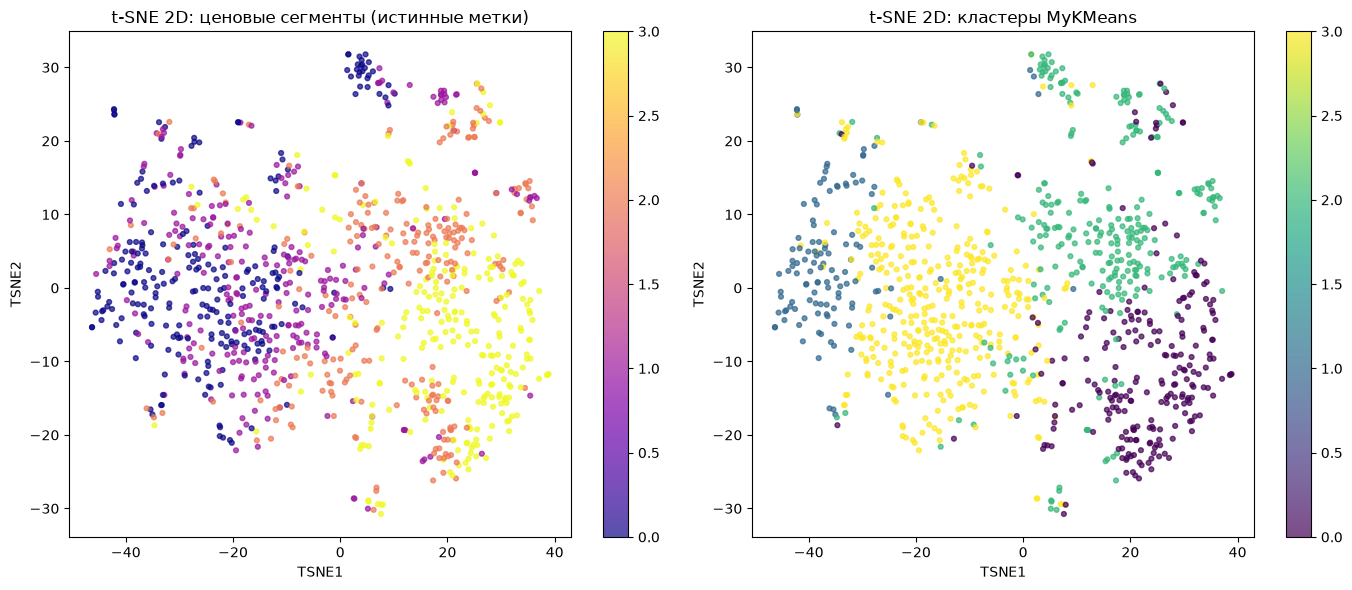

In [26]:
# Для ускорения t-SNE сначала снизим размерность PCA до 50 компонент
pca50 = PCA(n_components=50, random_state=42).fit_transform(X_train)
print(f"PCA 50 компонент объясняют {np.sum(pca_full.explained_variance_ratio_[:50]):.1%} дисперсии")

t0 = perf_counter()
tsne = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(pca50)
print(f"t-SNE выполнен за {perf_counter() - t0:.1f} с")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sc1 = axes[0].scatter(tsne[:, 0], tsne[:, 1], c=y_train, cmap="plasma", s=12, alpha=0.7)
axes[0].set_title("t-SNE 2D: ценовые сегменты (истинные метки)")
axes[0].set_xlabel("TSNE1"); axes[0].set_ylabel("TSNE2")
plt.colorbar(sc1, ax=axes[0])

sc2 = axes[1].scatter(tsne[:, 0], tsne[:, 1], c=my_final.labels_, cmap="viridis", s=12, alpha=0.7)
axes[1].set_title("t-SNE 2D: кластеры MyKMeans")
axes[1].set_xlabel("TSNE1"); axes[1].set_ylabel("TSNE2")
plt.colorbar(sc2, ax=axes[1])
plt.tight_layout()
plt.show()

In [27]:
print("Итоговая таблица (полная размерность, без PCA):")
final = pd.DataFrame({name: {
    "rand": metrics[name]["rand"][0],
    "silhouette": metrics[name]["silhouette"][0],
    "train_time, c": round(metrics[name]["train_time"][0], 3),
    "davies_bouldin": metrics[name]["davies_bouldin"][0],
} for name in models}).T.round(3)
print(final)

Итоговая таблица (полная размерность, без PCA):
                      rand  silhouette  train_time, c  davies_bouldin
MyKMeans             0.696       0.041          0.019           3.385
KMeans               0.686       0.038          0.100           3.089
AffinityPropagation  0.751      -0.032          0.553           0.883
DBSCAN               0.708      -0.088          0.042           2.455


## Выводы

- **Собственная реализация `MyKMeans` корректна**: при старте из одинаковых центроидов `sklearn.KMeans` даёт ровно ту же
  разметку (ARI = 1.0), а при одинаковом числе рестартов инерции практически совпадают (69168.7 vs 69150.3). Небольшие
  различия разметок (ARI = 0.74) объясняются разными потоками случайности при k-means++ и большим числом почти
  равнозначных локальных оптимумов (структура в данных слабая). Библиотечная версия при этом быстрее (написана на Cython).
- **Affinity Propagation** — самый медленный алгоритм (в разы дольше K-means). Он находит кластеры, лучше всего
  согласованные с ценовыми сегментами (Rand score ≈ 0.75 при любом числе компонент PCA), однако силуэт у него
  отрицательный — кластеры сильно пересекаются, часть объектов попадает в вырожденные группы. Число кластеров алгоритм
  выбирает сам.
- **DBSCAN** чувствителен к `eps`/`min_samples`: после агрессивного снижения размерности (5–15 компонент PCA)
  пространство становится слишком плотным и структура теряется (Rand score падает до 0.25–0.28). На полной размерности
  он работает не хуже K-means (0.708), но силуэт отрицательный из-за шумовых точек и несбалансированных кластеров.
- **PCA**: 50 главных компонент объясняют 90% дисперсии, при этом K-means сохраняет качество уже на 10–20 компонентах,
  а время обучения падает в разы (0.107 с → 0.006 с у `MyKMeans`). Для DBSCAN снижение размерности вредно — ему нужна
  полная размерность.
- **t-SNE** нагляднее PCA: на проекции видны несколько отдельных групп домов; квантильные ценовые сегменты хорошо ложатся
  на эти группы, т.е. кластеры, найденные без учителя, действительно соответствуют сегментам жилья по цене и качеству.
  PCA-проекция (2 компоненты объясняют лишь ~19% дисперсии) разделяет данные слабее, поскольку теряет много информации.
- Лучший баланс «качество/скорость» для этой задачи даёт **K-means**: стабильные кластеры, простые гиперпараметры и
  Rand score ≈ 0.69–0.72 против ценовых сегментов при кластеризации вообще без использования цен.